# WG6 Roman variable-star light curves: scoping (T28)
Regenerates every README figure from `data/` (no drive needed). Heavy work is in `tools/extract_wg6.py`, `tools/fetch_ogle_truth.py`, `tools/audit/wg6_{inventory,truth,profile,examples}.py`.

In [1]:
import sys, numpy as np, pandas as pd
from pathlib import Path
HERE = Path.cwd() if (Path.cwd()/'figlib.py').exists() else Path('reports/2026-11-12_wg6-dataset-scoping')
sys.path.insert(0, str(HERE))
import importlib, figlib; importlib.reload(figlib)
from figlib import *
inv = load_inventory(); b, s = load_profile()
truth = pd.read_csv(DATA/'truth_joined.csv.gz'); truth['cls']=truth['cls'].astype(str)
pc = pd.read_csv(DATA/'period_check.csv')
print(len(inv), 'stars;', len(s), 'profiled')

68824 stars; 524 profiled


## Counts per class (every file counted from its header)

         stars  median_points_all_bands  with_period  period_rate
cls                                                              
ROT       3172                  12379.0         3172     1.000000
FLARE      390                 211180.5          273     0.700000
ECL      47668                   7401.0        47660     0.999832
ELL       4227                   7351.0         4227     1.000000
HB          94                  12703.5           94     1.000000
RRLYR     6809                   6719.0         6809     1.000000
DSCT      1160                  11314.0         1149     0.990517
CEP         25                   1898.0           25     1.000000
T2CEP      224                   8374.5          224     1.000000
LPV       4373                   1906.0         4373     1.000000
VVV-LPV    401                     50.0            0     0.000000
BLAP         9                  14024.0            0     0.000000
DN         198                   5876.5            0     0.000000
TR        

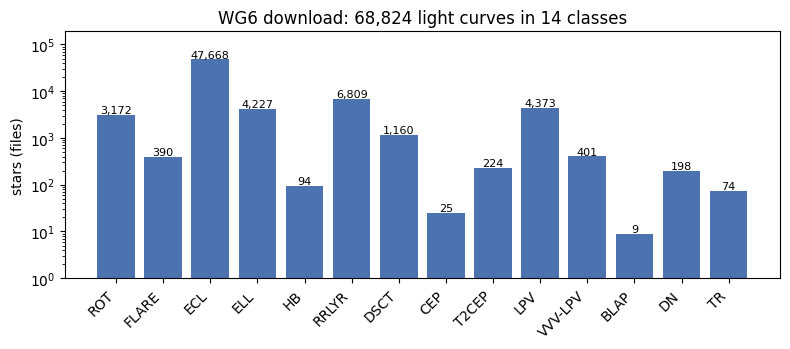

In [2]:
t = inv.groupby('cls').agg(stars=('NAME','size'), median_points_all_bands=('n_total','median')).reindex(ORDER).dropna()
rates = pd.read_csv(DATA/'truth_match_rates.csv', index_col=0)
t = t.join(rates[['with_period','period_rate']]); print(t.to_string()); print('total', int(t.stars.sum()))
fig_counts(inv);

## Per-class profile (primary band: OGLE I; TESS sector for flares), sample medians

In [3]:
I = b[(b.band=='LC_I') | ((b.cls=='FLARE') & (b.band=='0'))]
prof = I.groupby('cls')[['n','span_d','med_dt_min','n_seasons','med_season_len_d','med_season_n','med_y','p2p','med_err']].median()
pt = truth.groupby('cls').P_true.describe(percentiles=[.05,.5,.95])[['count','5%','50%','95%']]
prof = prof.join(pt).reindex(ORDER).dropna(how='all'); prof.round(3).to_csv(DATA/'profile_table.csv'); prof.round(3)

,n,span_d,med_dt_min,n_seasons,med_season_len_d,med_season_n,med_y,p2p,med_err,count,5%,50%,95%
cls,,,,,,,,,,,,,
ROT,12014.0,5106.988,59.411,14.0,266.630,781.75,16.653,0.013,0.010,3172.0,1.021,25.667,74.640
FLARE,89023.0,24.278,0.333,1.0,24.278,89023.00,11.145,0.005,0.005,273.0,0.323,1.400,124.088
ECL,7113.0,2071.635,56.894,6.0,270.627,898.00,18.084,0.060,0.027,47660.0,0.311,0.577,8.222
ELL,10528.5,2071.647,21.931,6.0,270.638,2222.75,16.506,0.016,0.008,4227.0,0.363,1.394,227.356
HB,12313.5,6661.863,36.277,22.0,252.415,255.00,13.772,0.003,0.009,94.0,128.073,245.519,437.140
RRLYR,6516.0,2714.771,67.295,8.0,268.638,824.00,17.600,0.059,0.016,6809.0,0.267,0.509,0.684
DSCT,14309.0,3526.649,23.918,10.0,268.638,1220.00,17.441,0.064,0.016,1149.0,0.049,0.075,0.151
CEP,1774.0,5065.011,1290.614,14.0,242.643,74.50,16.931,0.058,0.011,25.0,0.294,1.107,4.449
T2CEP,2121.0,4975.497,1117.660,14.0,242.643,79.00,16.483,0.032,0.008,224.0,1.249,8.520,36.660


## Truth periods per class vs the SMARTS range
Filled: catalog periods for every star; hatched: our top LS peak on the sample (only meaningful for classes without a catalog).

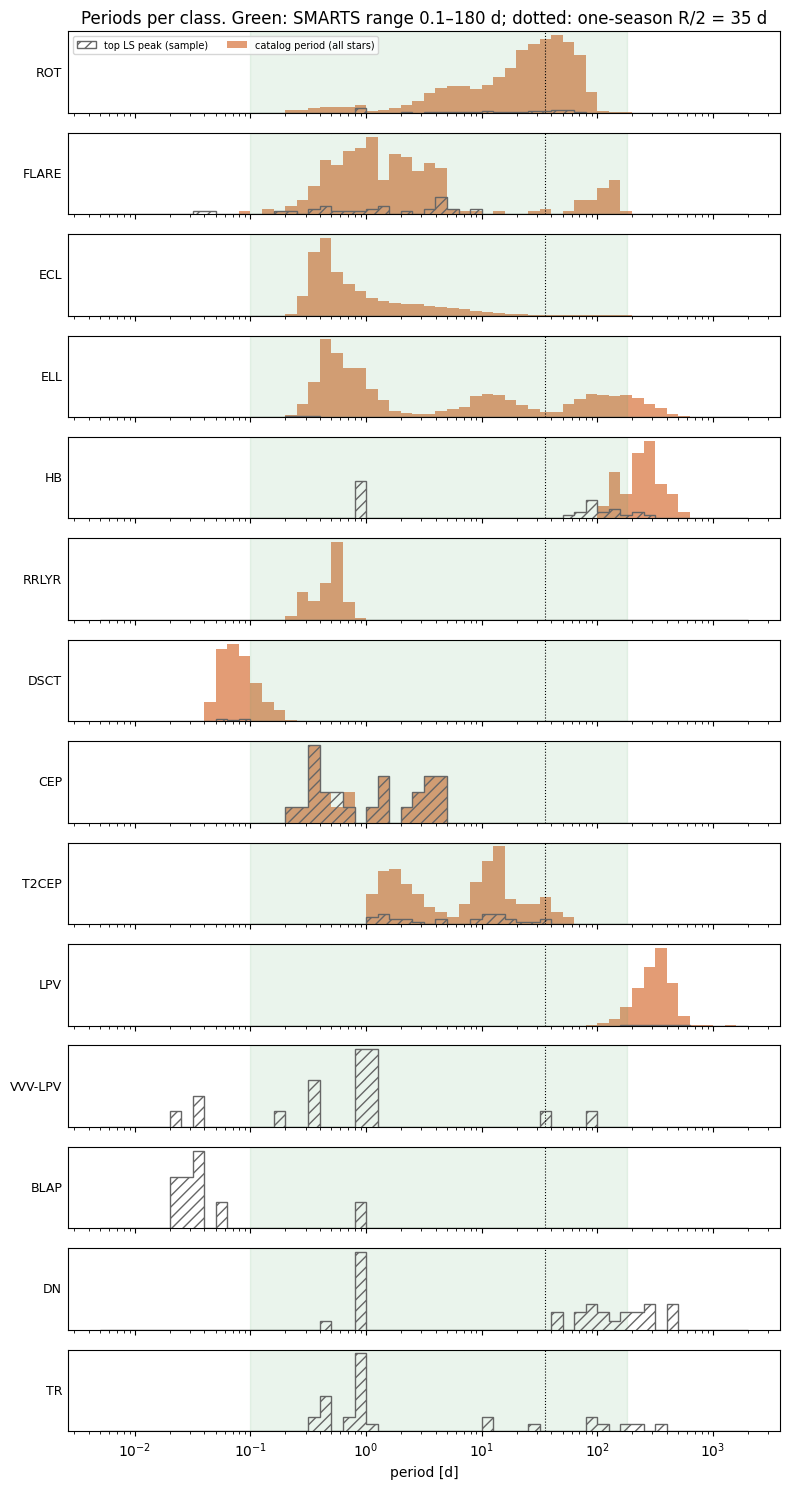

In [4]:
fig_periods(s, truth);

In [5]:
for c, g in truth.groupby('cls'):
    p = g.P_true.dropna()
    if len(p): print(f"{c:8s} n={len(p):6d}  frac 0.1-35 d: {((p>0.1)&(p<35)).mean():.2f}  frac 1-35 d: {((p>1)&(p<35)).mean():.2f}")

CEP      n=    25  frac 0.1-35 d: 1.00  frac 1-35 d: 0.52
DSCT     n=  1149  frac 0.1-35 d: 0.23  frac 1-35 d: 0.00
ECL      n= 47660  frac 0.1-35 d: 0.99  frac 1-35 d: 0.31
ELL      n=  4227  frac 0.1-35 d: 0.74  frac 1-35 d: 0.30
FLARE    n=   273  frac 0.1-35 d: 0.87  frac 1-35 d: 0.50
HB       n=    94  frac 0.1-35 d: 0.00  frac 1-35 d: 0.00
LPV      n=  4373  frac 0.1-35 d: 0.00  frac 1-35 d: 0.00
ROT      n=  3172  frac 0.1-35 d: 0.63  frac 1-35 d: 0.58
RRLYR    n=  6809  frac 0.1-35 d: 1.00  frac 1-35 d: 0.00
T2CEP    n=   224  frac 0.1-35 d: 0.94  frac 1-35 d: 0.94


## Noise vs magnitude
Point-to-point scatter (robust MAD of first differences / sqrt 2). For fast variables (DSCT, RRLYR, ECL) it includes real variability between consecutive points. Green band: SMARTS-TESS 30-min p2p over 100 dev files.

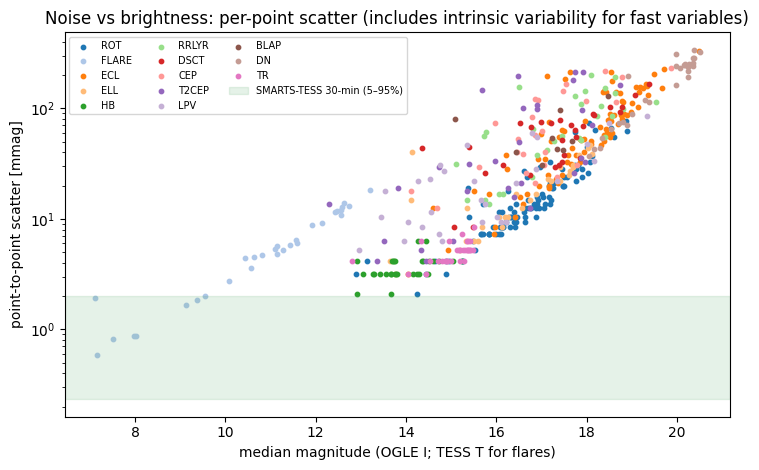

In [6]:
fig_noise(b);

## Example light curves and periodograms, one star per class

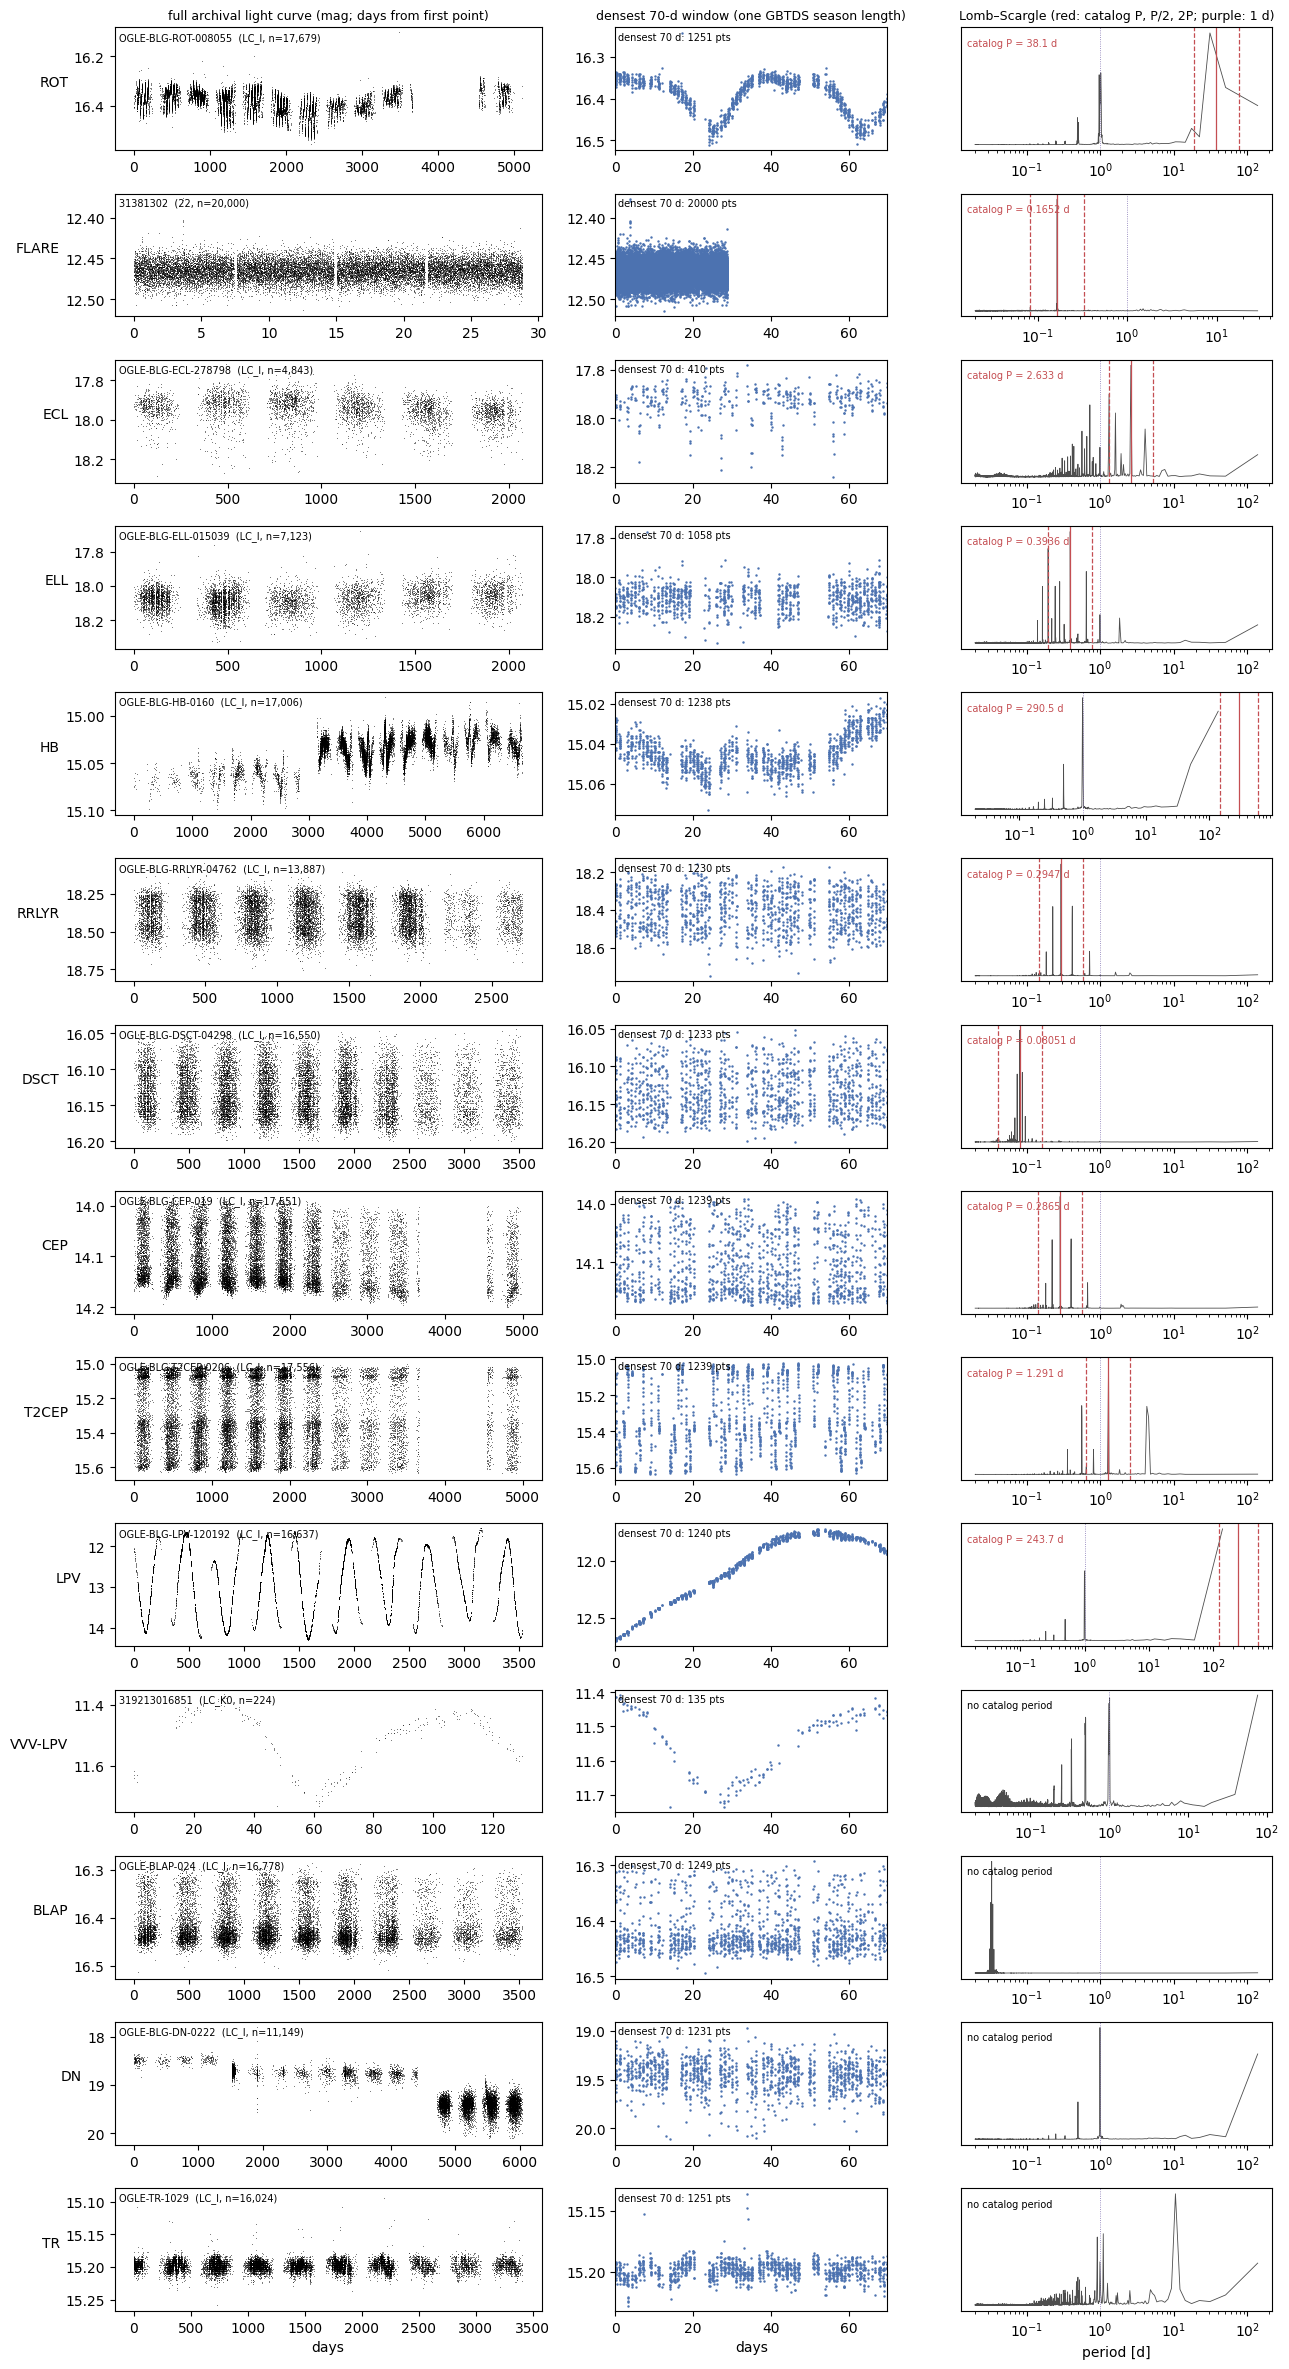

In [7]:
fig_examples();

## Time coverage for one star (ROT example) vs a GBTDS-like season

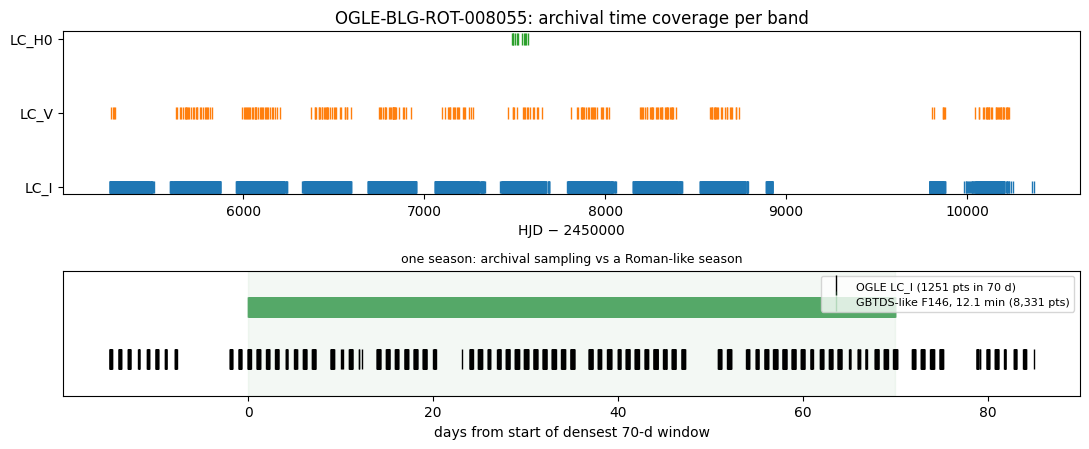

In [8]:
fig_coverage('ROT');

## Stored vs measured period
Our measured period = top Lomb–Scargle peak after skipping peaks at 0.95–1.05 d, 0.49–0.51 d and >300 d (ground-based daily/yearly window peaks), except LPV (periods >300 d are real) where the raw top peak is used.

outcome,2P,P/2,match,no measurement,other
cls,,,,,
BLAP,0,0,0,9,0
CEP,0,0,23,0,2
DN,0,0,0,30,0
DSCT,0,0,28,2,0
ECL,0,79,1,2,8
ELL,0,28,1,0,1
FLARE,1,1,14,8,6
HB,0,16,1,9,4
LPV,0,0,30,0,0


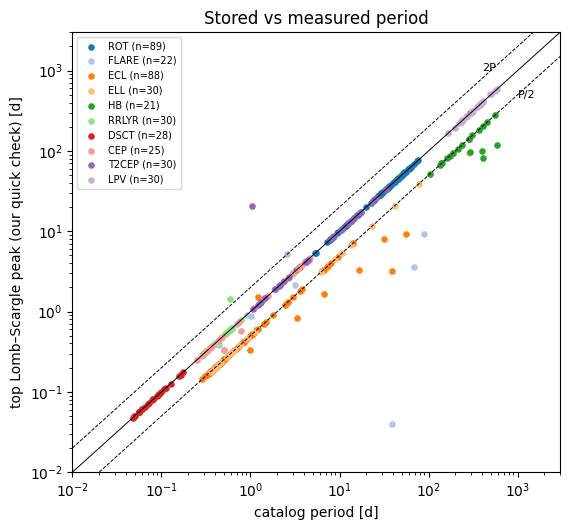

In [9]:
pc['P1_raw'] = pc['P1']
pc['P1'] = np.where(pc.cls.isin(['LPV']), pc.P1_raw, pc.P1c)
fig_period_check(pc)
def oc(r):
    if not (np.isfinite(r.P_true) and np.isfinite(r.P1)): return 'no measurement'
    x = r.P1/r.P_true
    for k,n in ((1,'match'),(0.5,'P/2'),(2,'2P')):
        if abs(x/k-1) < 0.1: return n
    return 'other'
pc['outcome'] = pc.apply(oc, axis=1)
tab = pd.crosstab(pc.cls, pc.outcome); tab.to_csv(DATA/'period_check_table.csv'); tab

## Pipeline timing (3 ROT stars, i5, one process)

In [10]:
tm = pd.read_csv(DATA/'pipeline_timing.csv'); print(tm[['NAME','P_true','input','fill_frac','n_acf_lags','seconds','P_found']].round(3).to_string())
sec = tm[tm.input.str.startswith('synthetic')].seconds.mean()
print(f'mean {sec:.2f} s/star -> all {len(inv):,} WG6 stars, one season each: {sec*len(inv)/3600:.1f} CPU-h; ROT only ({(inv.cls=="ROT").sum()}): {sec*(inv.cls=="ROT").sum()/60:.0f} CPU-min')

                  NAME  P_true                                    input  fill_frac  n_acf_lags  seconds  P_found
0  OGLE-BLG-ROT-006608   2.074         OGLE densest 70 d on 15-min grid      0.154          17    0.021      NaN
1  OGLE-BLG-ROT-006608   2.074         OGLE densest 70 d on 60-min grid      0.255        1176    0.012      NaN
2  OGLE-BLG-ROT-006608   2.074  synthetic 70 d at 12.1 min (Roman-like)      1.000        5831    0.834    2.074
3  OGLE-BLG-ROT-007851  16.012         OGLE densest 70 d on 15-min grid      0.183          19    0.018      NaN
4  OGLE-BLG-ROT-007851  16.012         OGLE densest 70 d on 60-min grid      0.304        1149    0.009      NaN
5  OGLE-BLG-ROT-007851  16.012  synthetic 70 d at 12.1 min (Roman-like)      1.000        5831    0.689   16.128
6  OGLE-BLG-ROT-007013  14.610         OGLE densest 70 d on 15-min grid      0.154          17    0.019      NaN
7  OGLE-BLG-ROT-007013  14.610         OGLE densest 70 d on 60-min grid      0.255        1176  